# Trotter分解による時間発展（量子回路）

量子コンピュータで実行できるのは、1〜2量子ビットに作用する小さなユニタリ（ゲート）の積と測定だけである。時間発展$e^{-iHt}$を量子回路で実行するために、**Trotter分解**でゲートの積に近似する手法が用いられる。

各模型への適用（ハミルトニアンの分け方、具体的な回路、その模型での誤差の特徴、手計算）は、`models/<模型>/03_trotter.ipynb` にまとめてある。

## 1. Trotter分解

ハミルトニアンが$H = \sum_{k} H_k$と、それぞれは扱いやすい項($H_k$)の和で書けているとする。各項が互いに交換関係にない（あるi, jで$\left[H_i, H_j\right]\neq0$）ならば$e^{-iHt}\neq\prod_k e^{-iH_kt}$であり、$e^{-iHt}$をそのまま簡単なゲートに分解することはできない。そこで次の公式（Lie-Trotter積公式）を使う。

\begin{equation}
e^{-i(A+B)t} = \lim_{r\to\infty}\left(e^{-iB\,\delta t}e^{-iA\,\delta t}\right)^r,\quad \delta t = \frac{t}{r}
\end{equation}

項が3つ以上でも同様に$e^{-iHt}\approx\left(\prod_k e^{-iH_k\delta t}\right)^r$とできる。この公式は、量子モンテカルロ法や偏微分方程式の数値解法などでも使われている。量子回路で役に立つのは、各$H_k$を**単独で**指数関数にしたものがゲートで書けるからである。

## 2. 指数関数をゲートにする

- **交換する項をまとめる**：互いに交換する項の和$H_k = \sum_a h_a P_a$（$P_a$はPauli演算子の積）なら、$e^{-iH_k\delta t} = \prod_a e^{-ih_aP_a\delta t}$とちょうど分解できる。そこで$H$を「中の項がすべて交換するグループ」に分け、グループごとに指数関数をとる。

  一般に$e^{A+B}\neq e^Ae^B$であるが、$[A,B]=0$なら指数法則$e^{A+B}=e^Ae^B$が近似なしで成り立つ。一方、$[A,B]\neq0$のときはBCH公式
  \begin{equation}
  e^{A}e^{B} = e^{A+B+\frac{1}{2}[A,B]+\cdots}
  \end{equation}
  より$O(\delta t^2)$のずれが生じる。これがTrotter誤差であり、近似が入るのはグループとグループの間だけである。

  Pauli演算子の積$P_a, P_b$は、必ず交換するか反交換するかのどちらかである。どちらになるかは、同じ量子ビットの上で異なるPauli（$X$と$Z$など）がぶつかる箇所の数で決まる。

  - 偶数個なら交換する（$[P_a,P_b]=0$）
  - 奇数個なら反交換する（$\{P_a,P_b\}=0$）

  たとえば$X_0X_1$と$Z_0Z_1$は量子ビット0と1の2箇所でぶつかるので交換し、$Z_0Z_1$と$X_1$は1箇所なので反交換する。

  **例1：横磁場イジングモデル**　$H = -J\sum_i Z_iZ_{i+1} - h\sum_i X_i$の場合

  - $Z_iZ_{i+1}$同士：$Z$しかないのでぶつかる箇所は0個であり、すべて交換する
  - $X_i$同士：同様にすべて交換する
  - $Z_iZ_{i+1}$と$X_i$：1箇所でぶつかるので交換しない

  そこで$H_{ZZ} = -J\sum_i Z_iZ_{i+1}$、$H_X = -h\sum_i X_i$の2グループに分けると、
  \begin{equation}
  e^{-iH\delta t} \approx e^{-iH_{ZZ}\delta t}\,e^{-iH_X\delta t},\qquad
  e^{-iH_{ZZ}\delta t} = \prod_i e^{iJ\delta t\,Z_iZ_{i+1}},\quad
  e^{-iH_X\delta t} = \prod_i e^{ih\delta t\,X_i}
  \end{equation}
  となる。右の2式は厳密であり、近似が入るのは左の式（$H_{ZZ}$と$H_X$の間）だけである。

  **例2：$H = J\sum_i X_iY_{i+1}$の場合**

  - 離れたボンド同士：量子ビットが重ならないので交換する
  - 隣り合うボンド$X_iY_{i+1}$と$X_{i+1}Y_{i+2}$：量子ビット$i+1$で$Y$と$X$が1箇所ぶつかるので交換しない。実際、
  \begin{equation}
  [X_0Y_1,\ X_1Y_2] = X_0(Y_1X_1 - X_1Y_1)Y_2 = -2i\,X_0Z_1Y_2 \neq 0
  \end{equation}

  したがって、この場合は$XY$の項だけで1つのグループにはできない。偶数ボンドと奇数ボンドに分けると、各グループの中はすべて交換するので、
  \begin{equation}
  \begin{aligned}
  e^{-iH\delta t} \approx e^{-iH_{XY\text{偶}}\delta t} e^{-iH_{XY\text{奇}}\delta t} = \prod_{i\,\text{偶数}} e^{-iJ\delta t\,X_iY_{i+1}} \prod_{i\,\text{奇数}} e^{-iJ\delta t\,X_iY_{i+1}}
  \end{aligned}
  \end{equation}
  となる。例1と同じく、グループの中は厳密で、グループの間だけが近似である。

  なお$\sum_i X_iX_{i+1}$や$\sum_i Y_iY_{i+1}$は、共有する量子ビットに同じPauliが並ぶのですべて交換し、1つのグループにできる。厳密に分解できるかどうかはPauliの種類ではなく、交換するかどうかで決まる。

- **Pauli演算子の積の指数関数**：$e^{-i\theta P}$は次のように回路にできる。
  1. $P$に含まれる$X$は$H$ゲート、$Y$は$S^\dagger$と$H$ゲートで$Z$に変換する（基底変換）
  2. 対象の量子ビットのパリティをCNOTで1つの量子ビットに集め、$R_Z(2\theta)$をかける
  3. 1と2の逆をかけて戻す

  特に1〜2量子ビットの場合はそのままゲートになる。

  \begin{equation}
  e^{-i\theta X} = R_X(2\theta),\quad e^{-i\theta Z} = R_Z(2\theta),\quad e^{-i\theta Z\otimes Z} = R_{ZZ}(2\theta)
  \end{equation}

  ここで$R_X(\theta) = e^{-i\frac{\theta}{2}X}$、$R_{ZZ}(\theta) = e^{-i\frac{\theta}{2}Z\otimes Z}$などはQiskitの標準ゲートである。

  **例：$P = X_0 Y_1 Z_2$ の場合**

  $e^{-i\theta X_0Y_1Z_2}$を上の手順で作る。

  1. 基底変換：$q_0$の$X$は$H$で、$q_1$の$Y$は$S^\dagger$→$H$の順にかけて$Z$に変換する。$q_2$はもともと$Z$なので何もしない。基底変換を$V$とまとめると、$V^\dagger (Z_0Z_1Z_2) V = X_0Y_1Z_2$となる。
  2. パリティを集める：CNOT($q_0\to q_1$)、CNOT($q_1\to q_2$)で$q_2$に$b_0\oplus b_1\oplus b_2$を書き込み、$R_Z(2\theta)$をかける。$Z_0Z_1Z_2$の固有値は$(-1)^{b_0\oplus b_1\oplus b_2}$なので、これで$e^{-i\theta Z_0Z_1Z_2}$になる。
  3. 戻す：CNOTを逆順にかけ、$q_0$に$H$、$q_1$に$H$→$S$をかける。

  \begin{equation}
  e^{-i\theta X_0Y_1Z_2} = V^\dagger\, e^{-i\theta Z_0Z_1Z_2}\, V,\qquad V = H_0\,(H_1S_1^\dagger)
  \end{equation}

  なお、量子回路は以下のようある。

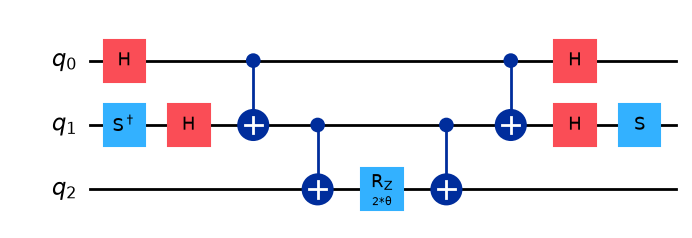

In [3]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Operator, SparsePauliOp

theta = Parameter("θ")
qc = QuantumCircuit(3)

# 1. 基底変換（X→Z, Y→Z）
qc.h(0)
qc.sdg(1)
qc.h(1)

# 2. パリティを q2 に集めて RZ(2θ)
qc.cx(0, 1)
qc.cx(1, 2)
qc.rz(2 * theta, 2)
qc.cx(1, 2)
qc.cx(0, 1)

# 3. 基底変換を戻す
qc.h(0)
qc.h(1)
qc.s(1)

display(qc.draw("mpl"))

- **並列化**：重ならない量子ビットに作用するゲートは同時にかけられるので、局所的なハミルトニアンなら1ステップの回路の深さを$n$によらない定数にできる。

## 3. Trotter誤差

Trotter分解は$r$が有限だと近似になる。2つの指数関数の積はBaker-Campbell-Hausdorff（BCH）公式より

\begin{equation}
e^{-iB\,\delta t}e^{-iA\,\delta t} = \exp\left[-i\delta t\left(A + B - \frac{i\delta t}{2}[B, A] + O(\delta t^2)\right)\right]
\end{equation}

となるので、1ステップごとに$O(\delta t^2)$の誤差が出る。$r$ステップでは誤差が積み重なり

\begin{equation}
\left\| e^{-i(A+B)t} - \left(e^{-iB\delta t}e^{-iA\delta t}\right)^r \right\| \le \frac{t^2}{2r}\left\|[A, B]\right\| = O\left(\frac{t^2}{r}\right)
\end{equation}

となる（**1次のTrotter分解**）。誤差を$\epsilon$以下にするには$r\sim t^2/\epsilon$ステップ、つまり誤差の逆数に比例するゲート数が必要になる。

両側を半分ずつにした**2次のTrotter分解**（鈴木分解）

\begin{equation}
e^{-i(A+B)\delta t} \approx e^{-iB\delta t/2}\,e^{-iA\delta t}\,e^{-iB\delta t/2}
\end{equation}

では$[B,A]$の項が打ち消し合い、誤差は$O(t^3/r^2)$に改善する。1ステップあたりのゲート数はほとんど変わらない。

さらに高次の分解（鈴木の高次公式）も作れ、$2k$次の分解では誤差が$O(t^{2k+1}/r^{2k})$になる。ただし1ステップあたりのゲート数が増えるので、精度とゲート数のバランスで選ぶ。

## 4. 測定

量子コンピュータで直接測れるのは、各量子ビットの$Z$基底の測定結果（0か1）だけである。Pauli演算子の積$P$の期待値を測るには、2節と同じ基底変換で$P$の各成分を$Z$に直してから測定し、結果のビット$b_j$から$Z_j = 1-2b_j = \pm1$の積をとる。これを多数回（ショット数$N_{\mathrm{shot}}$回）繰り返して平均すれば期待値の推定値になり、統計誤差は$1/\sqrt{N_{\mathrm{shot}}}$程度である。シミュレータでは状態ベクトルから期待値を直接計算することもできる。

---
**前へ**: [02 Jordan-Wigner変換](02_jordan_wigner.ipynb)　｜　**次へ**: [04 VQE](04_vqe.ipynb)